# Task 3: Test-time compute (Google Colab)

Live MATH generation with Qwen2.5-3B-Instruct (FP16, about 6 GB) runs on the GPU while the offline selection and adaptive-sampling analysis runs on the CPU.

## Setup

In [1]:
import os
import subprocess
import sys

from google.colab import drive

drive.mount("/content/drive")
SAVE = "/content/drive/MyDrive/atml-pa3"
os.makedirs(SAVE + "/results", exist_ok=True)

REPO = "/content/atml-pa3"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "https://github.com/syeddaniyalg/atml-pa3", REPO], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)

# results (including the per-question live records) live on Drive so a disconnect can resume;
# the downloaded data and the model cache stay on the fast local disk
os.environ["PA3_RESULTS"] = SAVE + "/results"
os.environ["PA3_CACHE"] = "/content/cache"
os.environ["HF_HOME"] = "/content/cache/hf"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

Mounted at /content/drive


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!df -h /content | tail -1
!nproc

name, memory.total [MiB]
Tesla T4, 15360 MiB
overlay         113G  335M  113G   1% /
2


## Supplied rollouts

In [3]:
from task3.config import download_data

print(download_data())

Retrieving folder contents


Retrieving folder 1Nqtmbk1eriY3B-qAlv7dgPvmc2Uo8ffI qwen25-math
Processing file 1SaWxZ4mpycw2BWZ5G0dahoYZ6Hh8tPWP generations.parquet
Processing file 1RCYHrTnUKtF7gHLSTe92x6W9ZsCOekfQ probability_metrics.parquet
Retrieving folder 1hr1BDTBT2PUqkhy8WRsCFOqNJHMMUYZn qwen25vl-mathvista
Processing file 1Nzg2VwE2qFzA10BF1lTxEcBZCePBe51q attention_metrics.parquet
Processing file 1sedMpWLI_UgPvAQVj7tS3HYVH0ARS1yA generations.parquet
Processing file 1f2XAu_J5NviYHEhtkRrFbKc7b2us1WiW probability_metrics.parquet
Processing file 1ZuUjXRtePOMKJYhj0BnZ4NuThXpwMLbK .DS_Store
Processing file 1RARGiUK_jZpOii-b8kyGLoejaldMUAa3 README.MD


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1SaWxZ4mpycw2BWZ5G0dahoYZ6Hh8tPWP
To: /content/cache/task3/ATML-PA3-Data/qwen25-math/generations.parquet
100%|██████████| 26.9M/26.9M [00:00<00:00, 30.2MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1RCYHrTnUKtF7gHLSTe92x6W9ZsCOekfQ
From (redirected): https://drive.google.com/uc?id=1RCYHrTnUKtF7gHLSTe92x6W9ZsCOekfQ&confirm=t&uuid=702c8279-9124-45f0-abcb-0aa5077c2d6c
To: /content/cache/task3/ATML-PA3-Data/qwen25-math/probability_metrics.parquet
100%|██████████| 155M/155M [00:05<00:00, 27.3MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1Nzg2VwE2qFzA10BF1lTxEcBZCePBe51q
From (redirected): https://drive.google.com/uc?id=1Nzg2VwE2qFzA10BF1lTxEcBZCePBe51q&confirm=t&uuid=c64ff831-9743-482a-bb85-d2cc86a473b8
To: /content/cache/task3/ATML-PA3-Data/qwen25vl-mathvista/attention_metrics.parquet
100%|

/content/cache/task3/ATML-PA3-Data



Download completed


## Quick Check

Two live questions, to confirm the model loads and generation works before the full run.

In [4]:
!python -m task3.run --stage live --live-limit 2
# the live job is skipped when live_summary.json exists, so remove the 2-question summary;
# the two records stay and the full run continues from question 3
os.remove(os.environ["PA3_RESULTS"] + "/task3/live_summary.json")

08:38:20 | task3 | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
08:38:24 | task3-live | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
tokenizer_config.json: 7.30kB [00:00, 27.3MB/s]
vocab.json: 2.78MB [00:00, 68.3MB/s]
merges.txt: 1.67MB [00:00, 108MB/s]
tokenizer.json: 7.03MB [00:00, 128MB/s]
config.json: 100% 661/661 [00:00<00:00, 5.58MB/s]
`torch_dtype` is deprecated! Use `dtype` instead!
I0000 00:00:1794559107.514984    1555 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794559110.136232    

## Run

`--stage all` runs live generation on the GPU alongside the offline analysis, then the plots. Live generation skips questions already in `live_records.jsonl`.

In [5]:
!python -m task3.run --stage all --workers 2

08:45:28 | task3 | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
[live|gpu0] start: -m task3.live
answer groups:  14%|█████████████████▎                                                                                                            | 137/1000 [00:11<01:10, 12.30q/s][live|gpu0] 08:45:49 | task3-live | env: {'torch': '2.14.1+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
[live|gpu0] `torch_dtype` is deprecated! Use `dtype` instead!
[live|gpu0] WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
[live|gpu0] I0000 00:00:1794559558.007958    3578 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
[live|gpu0] To enable the fol

## Results

,strategy,accuracy,input_tokens_per_q,output_tokens_per_q,seconds_per_q,truncation_rate_per_response,extraction_rate,peak_mem_gb
0,long,0.58,108.38,759.68,40.252140,0.040000,0.960000,5.893126
1,parallel,0.58,325.14,1840.38,88.303298,0.146667,0.853333,5.893126
2,refine,0.62,876.54,1229.36,59.600547,0.090000,1.000000,5.893126


,dataset,policy,accuracy,tokens,rollouts,accuracy_lo,accuracy_hi
0,math,fixed32,0.739125,21347.017500,32.0000,NaN,NaN
1,math,agreement,0.737625,10136.945875,11.8205,NaN,NaN
2,math,quality,0.733000,7663.055375,9.0075,NaN,NaN
3,math,fixed_sc_N1,0.644250,669.772625,1.0000,NaN,NaN
4,math,fixed_sc_N2,0.644250,1339.865500,2.0000,NaN,NaN
5,math,fixed_sc_N4,0.693250,2679.694125,4.0000,NaN,NaN
6,math,fixed_sc_N8,0.719125,5344.108500,8.0000,NaN,NaN
7,math,fixed_sc_N16,0.732375,10677.742750,16.0000,NaN,NaN
8,math,fixed_sc_N32,0.739125,21347.017500,32.0000,NaN,NaN
9,math,agreement_minus_fixed32,-0.001500,-11210.071625,-20.1795,-0.005000,0.001500


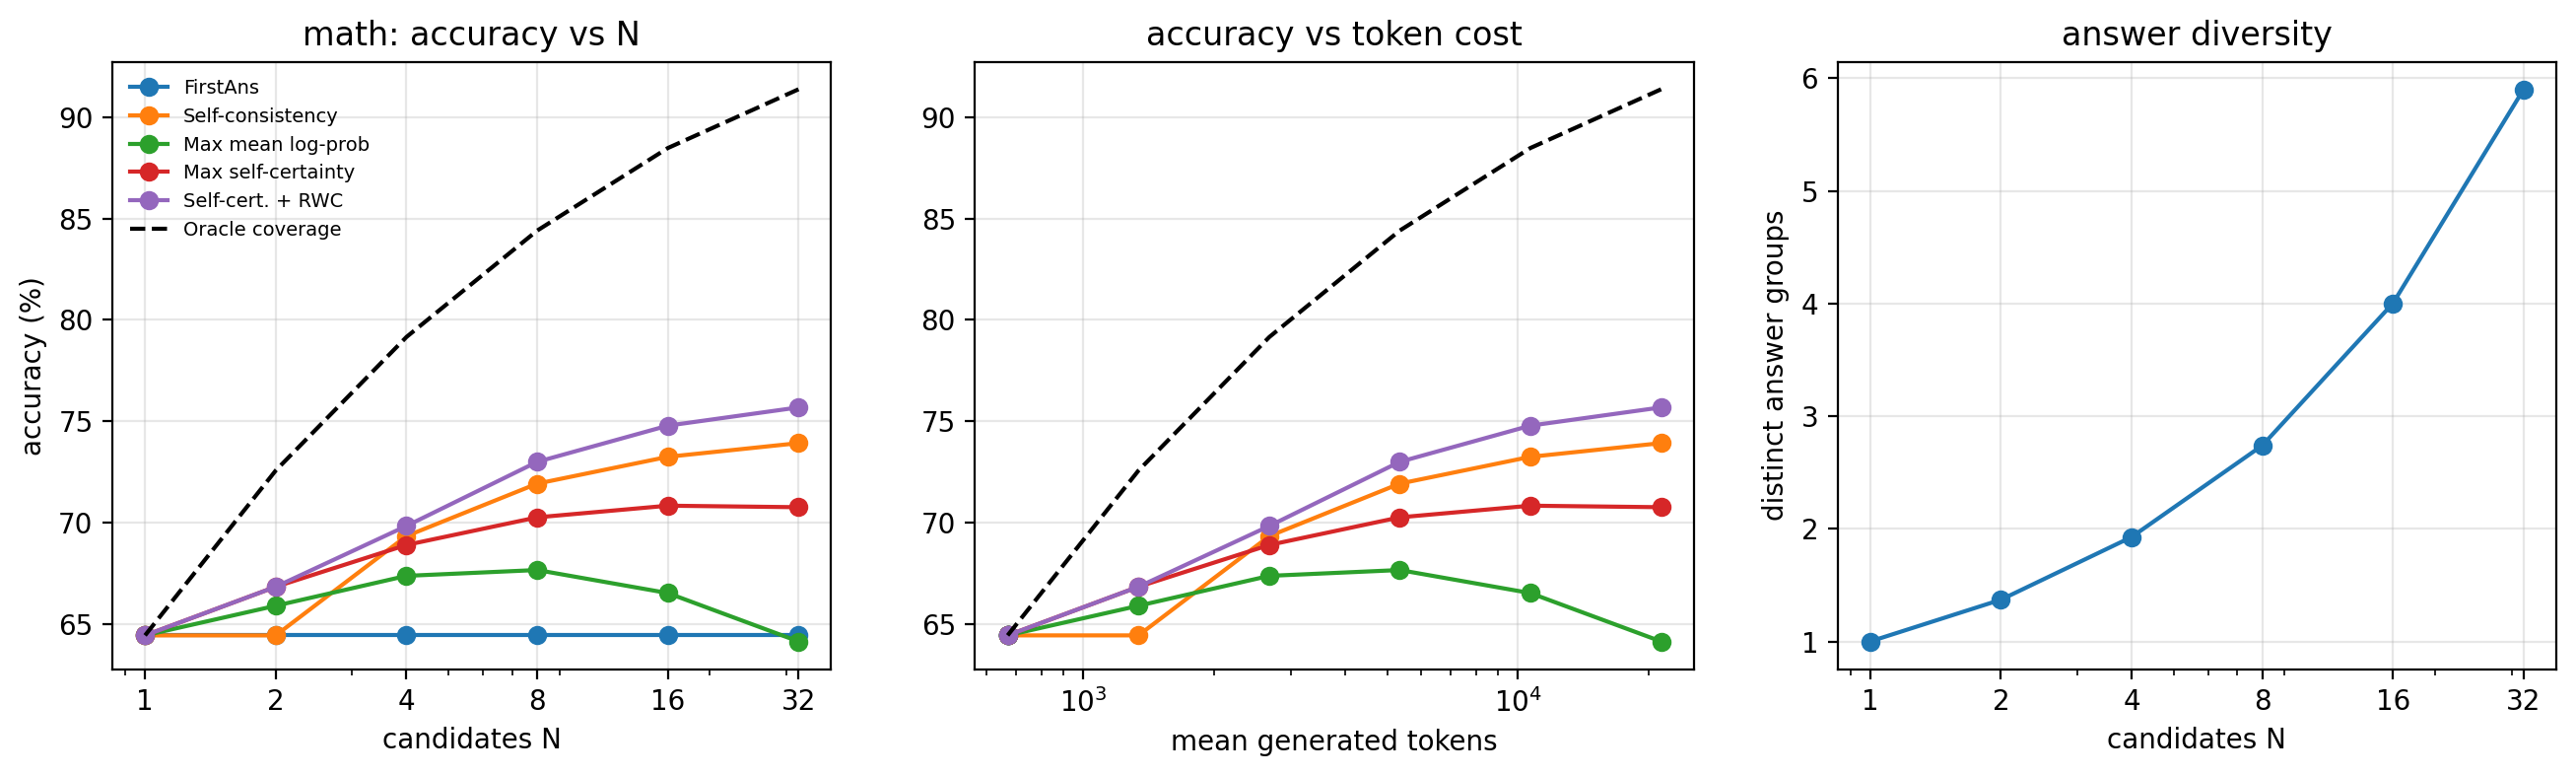

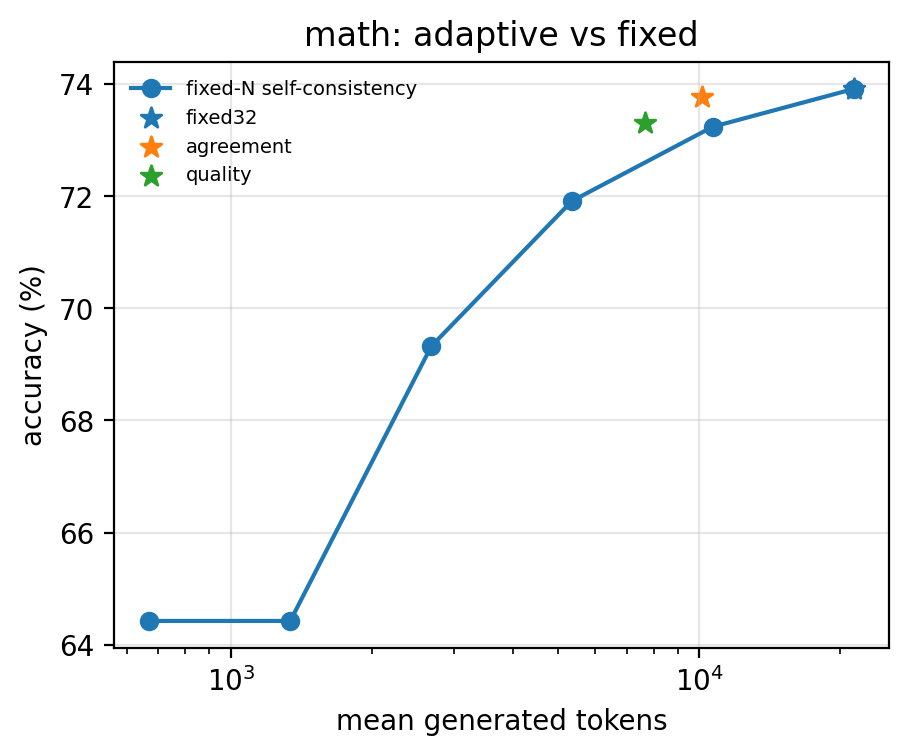

,dataset,policy,accuracy,tokens,rollouts,accuracy_lo,accuracy_hi
0,mathvista,fixed32,0.639250,8897.757500,32.000,NaN,NaN
1,mathvista,agreement,0.630250,2919.400125,8.391,NaN,NaN
2,mathvista,quality,0.634000,3279.706000,9.568,NaN,NaN
3,mathvista,fixed_sc_N1,0.544875,277.796375,1.000,NaN,NaN
4,mathvista,fixed_sc_N2,0.544875,551.250125,2.000,NaN,NaN
5,mathvista,fixed_sc_N4,0.589375,1111.591625,4.000,NaN,NaN
6,mathvista,fixed_sc_N8,0.613750,2229.902000,8.000,NaN,NaN
7,mathvista,fixed_sc_N16,0.627000,4461.842500,16.000,NaN,NaN
8,mathvista,fixed_sc_N32,0.639250,8897.757500,32.000,NaN,NaN
9,mathvista,agreement_minus_fixed32,-0.009000,-5978.357375,-23.609,-0.01975,0.002128


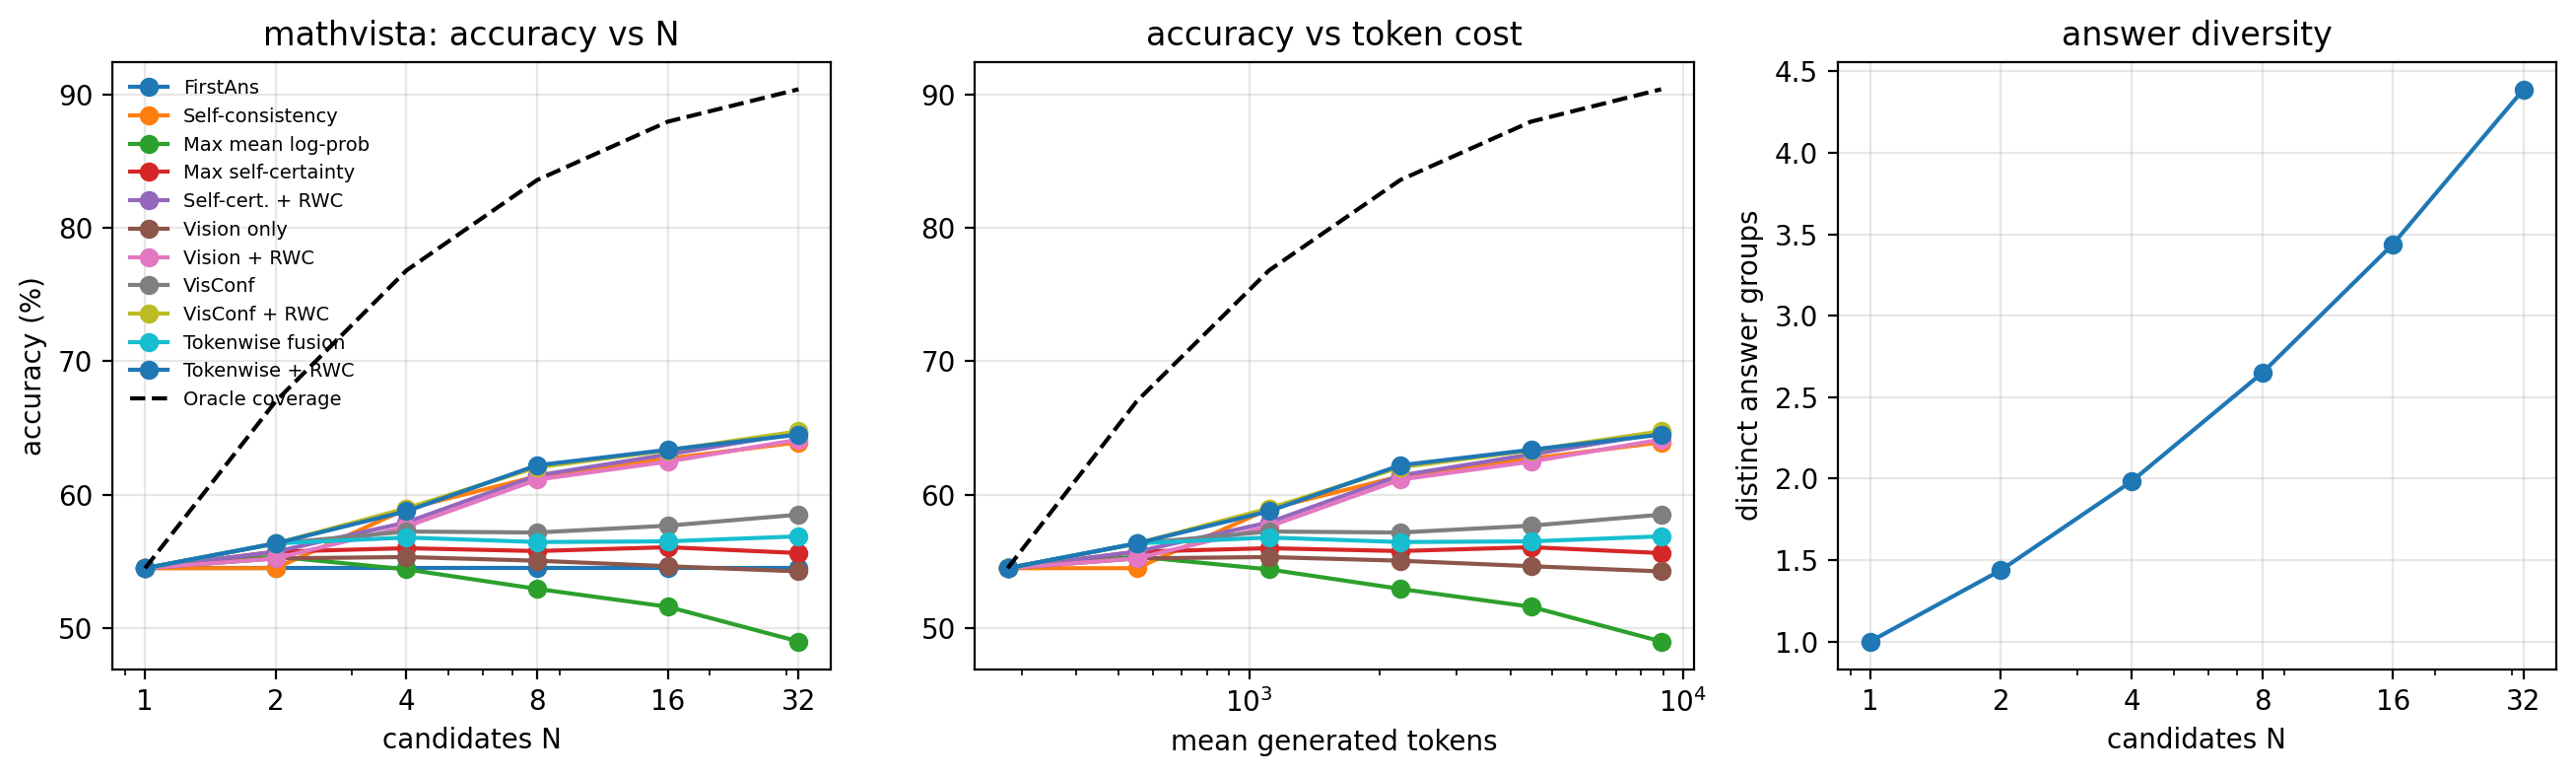

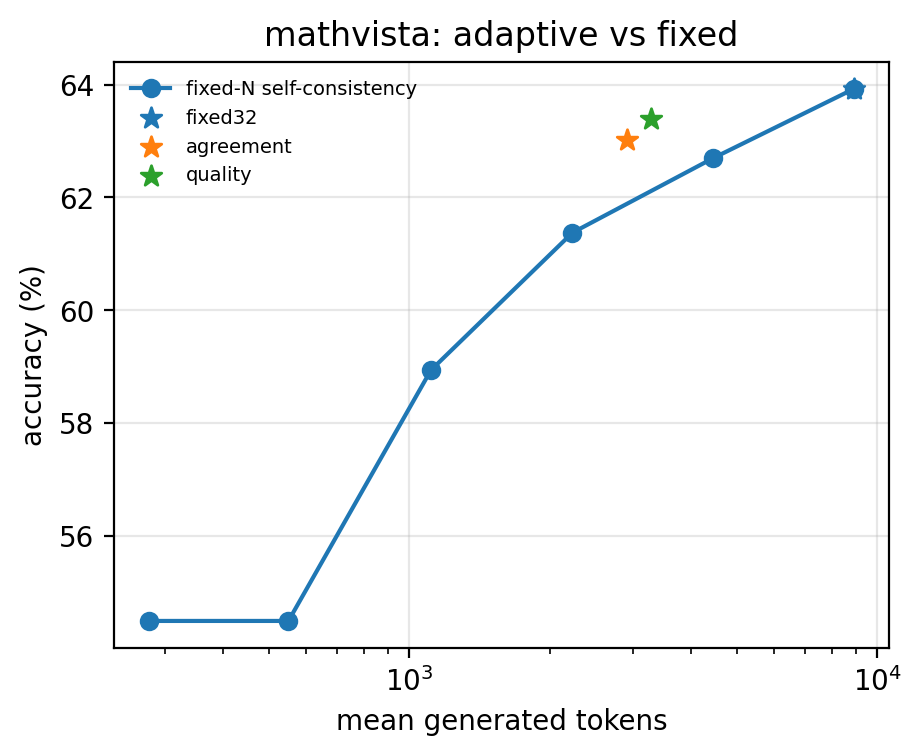

In [6]:
import pandas as pd
from IPython.display import Image, display

R = os.environ["PA3_RESULTS"] + "/task3"
display(pd.read_csv(f"{R}/live_strategies.csv"))
for ds in ["math", "mathvista"]:
    display(pd.read_csv(f"{R}/adaptive_heldout_{ds}.csv"))
    display(Image(f"{R}/figures/accuracy_curves_{ds}.png"))
    display(Image(f"{R}/figures/adaptive_{ds}.png"))